In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision.ops import box_iou

from challenge.dataset import Dataset, yolo_to_xyxy, yolo_to_xyxy_torch
from challenge.visuals import add_yolo_boxes, plot_image_with_boxes

In [2]:
train_data = Dataset("../data/data_notebook.yaml", split="train")
val_data = Dataset("../data/data_notebook.yaml", split="val")

In [3]:
seed = 42
rng = np.random.default_rng(seed)

WIN_W = 64
WIN_H = 128

winSize = (WIN_W, WIN_H)
blockSize = (32, 32)
blockStride = (16, 16)
cellSize = (16, 16)
nbins = 9

num_samples = 1000

In [4]:
idx = rng.integers(low=0, high=len(train_data), size=500)
tiny_train = [train_data[i] for i in idx]
idx = rng.integers(low=0, high=len(val_data), size=100)
tiny_val = [val_data[i] for i in idx]

In [ ]:
import numpy as np


class PatchSampler:
    def __init__(
        self,
        *,
        target_class: int,
        window_size: tuple[int, int],
        positive_margin: float = 1.2,
        min_box_size: int = 20,
        negatives_per_image: int = 20,
        negative_iou_thresh: float = 0.2,
        rng: np.random.Generator | None = None,
        convert_to_gray: bool = True,
        interpolation: int = cv2.INTER_LINEAR,
    ):
        self.target_class = target_class
        self.win_w, self.win_h = window_size
        self.positive_margin = positive_margin
        self.min_box_size = min_box_size
        self.negatives_per_image = negatives_per_image
        self.negative_iou_thresh = negative_iou_thresh
        self.convert_to_gray = convert_to_gray
        self.interpolation = interpolation

        self.rng = rng if rng is not None else np.random.default_rng()

    def extract(self, dataset):
        X_pos, X_neg = [], []

        for sample in dataset:
            img = sample["image"]
            H, W = img.shape[:2]
            boxes = sample["targets"]

            X_pos.extend(self._extract_positives(img, boxes, H, W))
            X_neg.extend(self._extract_negatives(img, boxes, H, W))

        return X_pos, X_neg

    def _extract_positives(self, img, boxes, H, W):
        X_pos = []

        if len(boxes) == 0:
            return X_pos

        labels, boxes_xyxy = yolo_to_xyxy(boxes, H, W)

        for cls, (x1, y1, x2, y2) in zip(labels, boxes_xyxy):
            if int(cls) != self.target_class:
                continue

            cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            bw, bh = (x2 - x1), (y2 - y1)

            if bw < self.min_box_size or bh < self.min_box_size:
                continue

            bw *= self.positive_margin
            bh *= self.positive_margin

            ix1 = max(0, int(cx - bw / 2))
            iy1 = max(0, int(cy - bh / 2))
            ix2 = min(W, int(cx + bw / 2))
            iy2 = min(H, int(cy + bh / 2))

            patch = img[iy1:iy2, ix1:ix2]
            if patch.size == 0:
                continue

            X_pos.append(self._postprocess_patch(patch))

        return X_pos

    def _extract_negatives(self, img, boxes, H, W):
        X_neg = []

        if len(boxes) > 0:
            labels, boxes_xyxy = yolo_to_xyxy_torch(boxes, H, W)
            gt_xyxy = boxes_xyxy[labels == self.target_class]
        else:
            gt_xyxy = torch.empty((0, 4))

        ws = self.rng.integers(
            self.min_box_size,
            min(W // 2, H // 2),
            size=self.negatives_per_image,
        )
        hs = self.rng.integers(
            self.min_box_size,
            min(W // 2, H // 2),
            size=self.negatives_per_image,
        )

        xs = self.rng.integers(0, W - ws)
        ys = self.rng.integers(0, H - hs)

        proposals = torch.stack(
            [
                torch.from_numpy(xs),
                torch.from_numpy(ys),
                torch.from_numpy(xs + ws),
                torch.from_numpy(ys + hs),
            ],
            dim=1,
        ).float()

        if len(gt_xyxy) > 0:
            ious = box_iou(proposals, gt_xyxy)
            keep = ious.max(dim=1).values < self.negative_iou_thresh
        else:
            keep = torch.ones(len(proposals), dtype=torch.bool)

        for x1, y1, x2, y2 in proposals[keep].int().tolist():
            patch = img[y1:y2, x1:x2]
            if patch.size == 0:
                continue

            X_neg.append(self._postprocess_patch(patch))

        return X_neg

    def _postprocess_patch(self, patch):
        patch = cv2.resize(
            patch,
            (self.win_w, self.win_h),
            interpolation=self.interpolation,
        )

        if self.convert_to_gray:
            patch = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)

        return patch

In [27]:
sampler = PatchSampler(
    target_class=0,
    window_size=(64, 128),
    positive_margin=1.25,
    min_box_size=24,
    negatives_per_image=5,
    negative_iou_thresh=0.2,
    rng=np.random.default_rng(42),
)

X_pos, X_neg = sampler.extract(tiny_train)

In [28]:
len(X_pos), len(X_neg)

(123, 2402)

In [6]:
X_pos = extract_positives(tiny_train)
X_neg = extract_negatives(tiny_train)

In [7]:
X_pos_resized = []
X_neg_resized = []

for p in X_pos:
    p_resized = cv2.resize(p, (WIN_W, WIN_H))
    X_pos_resized.append(p_resized)
for n in X_neg:
    n_resized = cv2.resize(n, (WIN_W, WIN_H))
    X_neg_resized.append(n_resized)

X_pos_resized = [cv2.cvtColor(p, cv2.COLOR_RGB2GRAY) for p in X_pos_resized]
X_neg_resized = [cv2.cvtColor(n, cv2.COLOR_RGB2GRAY) for n in X_neg_resized]
print(len(X_pos_resized), len(X_neg_resized))

123 418


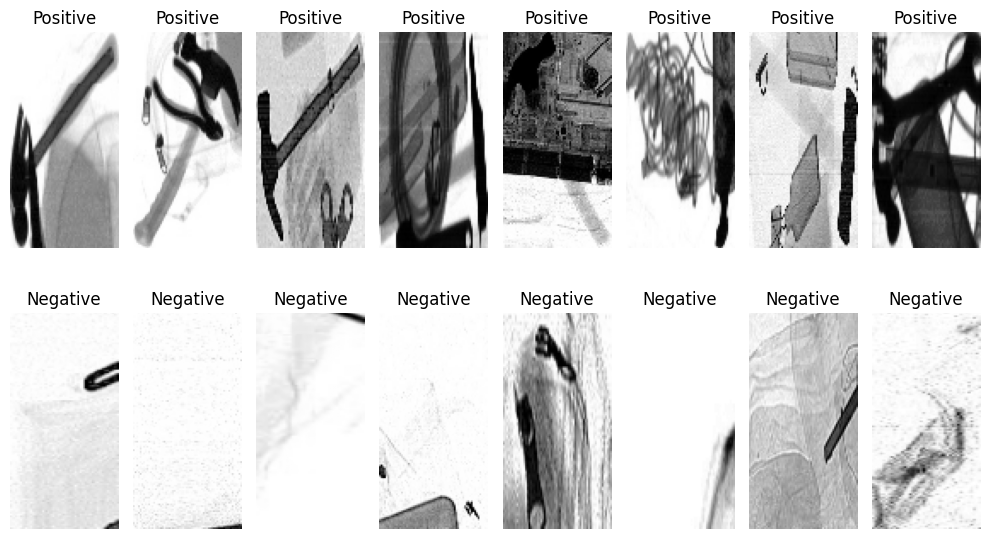

In [8]:
# number of examples per class to display
n_show = 8
fig, ax = plt.subplots(2, 8, figsize=(10, 6))
ax = ax.flatten()

pos_idx = rng.choice(range(len(X_pos_resized)), n_show)
neg_idx = rng.choice(range(len(X_neg_resized)), n_show)

for i, idx in enumerate(pos_idx):
    ax[i].imshow(X_pos_resized[idx], cmap="gray")
    ax[i].set_title("Positive")
    ax[i].axis("off")

for i, idx in enumerate(neg_idx):
    ax[i + n_show].imshow(X_neg_resized[idx], cmap="gray")
    ax[i + n_show].set_title("Negative")
    ax[i + n_show].axis("off")

plt.tight_layout()
plt.show()

In [9]:
images = X_pos_resized + X_neg_resized
labels = ([1] * len(X_pos_resized)) + ([0] * len(X_neg_resized))
hog = cv2.HOGDescriptor(winSize, blockSize, blockStride, cellSize, nbins)
data = []
for img in images:
    features = hog.compute(img)
    data.append(features.flatten())

data = np.array(data, dtype=np.float32)
labels = np.array(labels, dtype=np.int32)
print(data.shape, labels.shape)

(541, 756) (541,)


In [10]:
svm = cv2.ml.SVM_create()
svm.setType(cv2.ml.SVM_C_SVC)
svm.setKernel(cv2.ml.SVM_RBF)
svm.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER + cv2.TERM_CRITERIA_EPS, 10000, 1e-8))
svm.train(data, cv2.ml.ROW_SAMPLE, labels)

True

In [11]:
hog = cv2.HOGDescriptor(winSize, blockSize, blockStride, cellSize, nbins)
hog.setSVMDetector(svm.getSupportVectors()[0])

In [ ]:
pred_boxes = []
from tqdm import tqdm

for sample in tqdm(tiny_val):
    img = sample["image"]
    pred_boxes.append(hog.detectMultiScale(img))

100%|██████████| 100/100 [00:24<00:00,  4.10it/s]


In [16]:
pred_boxes

[(array([[321, 131,  88, 176]], dtype=int32), array([15.34082821])),
 (array([[181, 132,  87, 174]], dtype=int32), array([15.6300027])),
 (array([[151, 132,  87, 174]], dtype=int32), array([14.38988769])),
 (array([[260, 131,  88, 175]], dtype=int32), array([14.32024205])),
 (array([[191, 132,  87, 174]], dtype=int32), array([15.20149815])),
 (array([[181, 132,  87, 174]], dtype=int32), array([16.96321876])),
 (array([[694, 411, 100, 200]], dtype=int32), array([16.60879228])),
 (array([[141, 132,  87, 174]], dtype=int32), array([15.93831865])),
 (array([[371, 192,  92, 184]], dtype=int32), array([15.74891339])),
 (array([[202, 132,  88, 175]], dtype=int32), array([15.86524957])),
 (array([[141, 132,  87, 174]], dtype=int32), array([15.45304646])),
 (array([[132, 133,  87, 173]], dtype=int32), array([13.9670676])),
 (array([[122, 133,  86, 173]], dtype=int32), array([15.52931285])),
 (array([[251, 131,  88, 175]], dtype=int32), array([14.8267739])),
 (array([[141, 132,  87, 174]], dtype

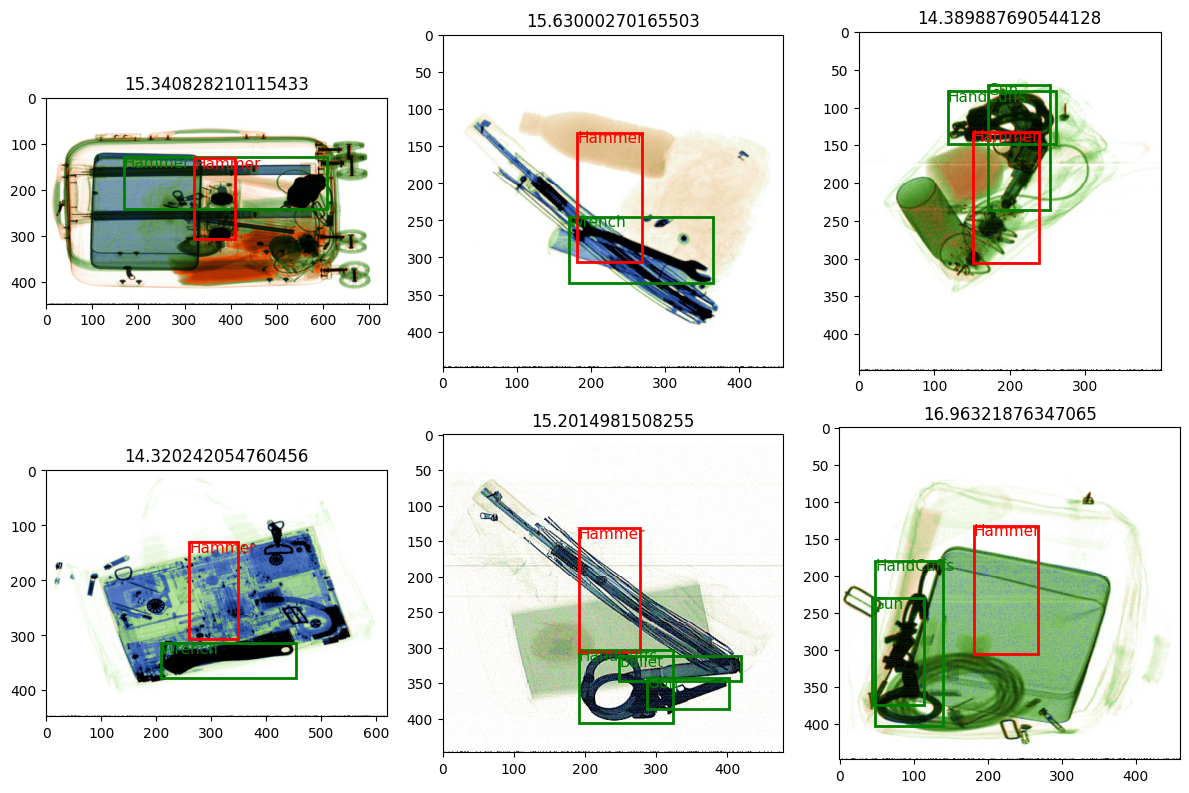

In [18]:
from challenge.dataset import xywh_to_yolo

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()
for i, sample in enumerate(tiny_val[:6]):
    img = sample["image"]
    plot_image_with_boxes(
        ax[i],
        sample["image"],
        sample["targets"],
        color="green",
    )
    scores = pred_boxes[i][1]
    boxes = pred_boxes[i][0]
    best_box = boxes[np.argmax(scores.flatten())]
    score = np.max(scores)
    add_yolo_boxes(
        ax[i],
        xywh_to_yolo(best_box[None, :], img.shape, 0),
        img.shape,
        color="red",
    )
    ax[i].set_title(score)

plt.tight_layout()
